## Abstract

Transformers trained on planetary orbits learn a Newtonian world model at short context and a Keplerian one at long context. We apply Equivalent Linear Mapping to decompose *how* the short-context model builds a Newtonian gravitational force from two past positions.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

Liu et al. (2025) showed that transformers trained to predict planetary motion learn qualitatively different *world models* depending on context length, and detected this with linear probes — which reveal *what* is encoded, but not *how* the network computes with it. Here we open the box: we apply **Equivalent Linear Mapping (ELM)** to rewrite the trained transformer as an exact per-token linear map and read the gravitational force directly out of its Jacobian. 

**The setup.** The training data is 2D planetary orbits under an inverse-square force, $\ddot{\mathbf r} = -\,\mathbf r/|\mathbf r|^{3}$ (units with $GM=1$). The transformer reads a sequence of past positions $\mathbf r_0, \mathbf r_1, \dots$ and predicts the next one, $\hat{\mathbf r}_{t+1}$. Its **context length** (block size) is how many past positions it may attend to. A **world model** here is the internal rule the network uses to make that prediction. Two alterantive world models can fit the training data with high fidelity:

- a **Newtonian** model — estimate the local gravitational force from the last one or two positions and integrate $\mathbf F = m\mathbf a$ (local, causal);
- a **Keplerian** model — fit the global ellipse through the observed points and continue along it (global, geometric).

Liu et al. found short context favours the Newtonian rule and long context the Keplerian one. @fig-setup sketches the task and these two candidate rules. **What we train.** We re-train Liu et al.'s model — a small GPT-2-style transformer (a modified nanoGPT) — from scratch at the two context lengths that bracket their result, **2** and **100**, using the noisy-context training (noise level $\sigma = 0.1$) that stabilises autoregressive prediction. Our one departure from their setup is that we disable every **bias term**: the ELM analysis below needs the network to be a *homogeneous* linear map at each operating point (no additive constants), which bias terms would spoil. Because bias-free training is non-standard, we check that it changes nothing essential — our bias-free checkpoints still reproduce the full Newton↔Kepler phase transition (@fig-phase-transition).

With the models in hand, our first two analyses set up the tools the rest of the pub relies on: (1) the ELM decomposition is *exact*, so its per-token attributions are trustworthy; and (2) linear probing reproduces the phase transition on these checkpoints — the entry point for asking *how* each model actually computes.


In [2]:
#| code-fold: true
#| output: false
import io
import os
import contextlib

import numpy as np
import torch
import matplotlib.pyplot as plt

from analysis.model import load_from_checkpoint

torch.set_default_dtype(torch.float64)   # ELM reconstruction is exact only at float64

CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'
DATA_DIR       = 'data_cv'
NUM_TRAJ, NOISE_SCALE, SEED = 10000, 0.1, 0
CKPT_BS2   = f'{CHECKPOINT_DIR}/model_block_size_2_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
CKPT_BS100 = f'{CHECKPOINT_DIR}/model_block_size_100_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'

with contextlib.redirect_stdout(io.StringIO()):
    model_bs2,   _ = load_from_checkpoint(CKPT_BS2,   device='cpu'); model_bs2.eval()
    model_bs100, _ = load_from_checkpoint(CKPT_BS100, device='cpu'); model_bs100.eval()


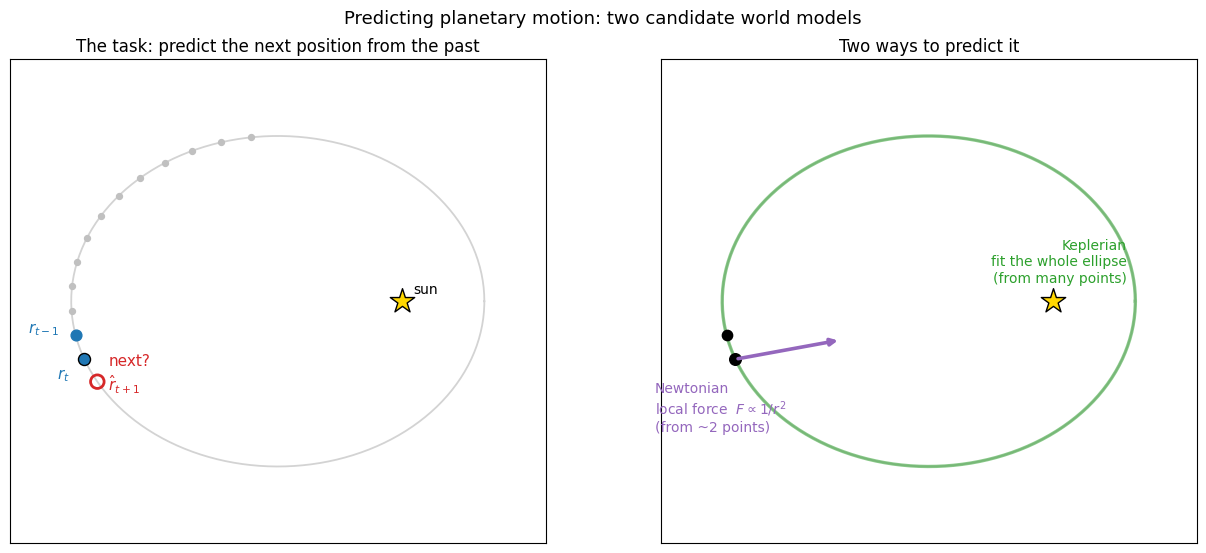

In [3]:
#| label: fig-setup
#| fig-cap: "The prediction task and the two candidate world models. Left: the transformer sees past positions along an orbit (blue = the two most recent) and must predict the next one. Right: a Newtonian rule estimates the local inverse-square force from the last couple of positions and integrates it; a Keplerian rule fits the global ellipse through many points and continues along the curve."
#| code-fold: true
_a, _e = 1.35, 0.6; _b = _a*np.sqrt(1-_e**2); _c = _a*_e
_E = np.linspace(0, 2*np.pi, 300); _ex, _ey = _a*np.cos(_E), _b*np.sin(_E); _sun = np.array([_c, 0.0])
_Es  = np.linspace(1.7, 3.5, 13)
_pts = np.stack([_a*np.cos(_Es), _b*np.sin(_Es)], 1)
_rp, _rt = _pts[-2], _pts[-1]
_En = 2*_Es[-1] - _Es[-2]; _rn = np.array([_a*np.cos(_En), _b*np.sin(_En)])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.6))
for ax in (axA, axB):
    ax.plot(_ex, _ey, color='lightgray', lw=1.3, zorder=0)
    ax.scatter(*_sun, marker='*', s=340, color='gold', edgecolor='k', zorder=6)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(-_a-0.4, _a+0.4); ax.set_ylim(-_b-0.5, _b+0.5)
axA.scatter(_pts[:-2, 0], _pts[:-2, 1], s=18, color='silver', zorder=3)
axA.scatter(*_rp, s=60, color='tab:blue', zorder=4); axA.scatter(*_rt, s=75, color='tab:blue', edgecolor='k', zorder=4)
axA.scatter(*_rn, s=95, facecolor='none', edgecolor='tab:red', lw=2, zorder=5)
axA.annotate(r'$r_{t-1}$', _rp, textcoords='offset points', xytext=(-34, 2), color='tab:blue', fontsize=11)
axA.annotate(r'$r_t$', _rt, textcoords='offset points', xytext=(-20, -14), color='tab:blue', fontsize=11)
axA.annotate('next?\n$\hat r_{t+1}$', _rn, textcoords='offset points', xytext=(8, -6), color='tab:red', fontsize=11)
axA.annotate('sun', _sun, textcoords='offset points', xytext=(8, 6), fontsize=10)
axA.set_title('The task: predict the next position from the past', fontsize=12)
axB.scatter(*_rp, s=55, color='k', zorder=4); axB.scatter(*_rt, s=70, color='k', edgecolor='k', zorder=4)
_d = _sun - _rt; _d = _d/np.linalg.norm(_d)*0.7
axB.annotate('', xy=_rt + _d, xytext=_rt, arrowprops=dict(arrowstyle='-|>', color='tab:purple', lw=2.6), zorder=5)
axB.annotate('Newtonian\nlocal force  $F\propto 1/r^2$\n(from ~2 points)', _rt, textcoords='offset points', xytext=(-58, -52), color='tab:purple', fontsize=10)
axB.plot(_ex, _ey, color='tab:green', lw=2.4, alpha=0.55, zorder=2)
axB.annotate('Keplerian\nfit the whole ellipse\n(from many points)', (_ex.max(), 0), textcoords='offset points', xytext=(-6, 14), color='tab:green', fontsize=10, ha='right')
axB.set_title('Two ways to predict it', fontsize=12)
fig.suptitle('Predicting planetary motion: two candidate world models', fontsize=13)
fig.tight_layout(); plt.show()


## Verifying the ELM decomposition

A transformer is nonlinear, so in general no single matrix maps its input to its output. But the nonlinearity is concentrated in a few *input-dependent* choices — how strongly each vector is normalised, which neurons the gates switch on, and where attention looks. **Equivalent Linear Mapping (ELM)** freezes those choices at the values they take for one specific input $x^*$ and *detaches* them from the gradient (Golden 2026). For that input the network then behaves as an exact linear map, which we can read off as a set of per-token Jacobian matrices $J_t(x^*)$ and interpret directly:

$$y^* \;=\; \sum_t J_t(x^*)\, x_t^* \qquad\text{(exact at }x^*\text{).}$$

This exact form is *homogeneous* — it carries no additive constant — which is precisely why we trained the models with all **bias terms disabled**: a bias would inject a constant offset that no per-token Jacobian could absorb, breaking the reconstruction. Disabling bias is a deviation from the standard architecture, but it does not change the phenomenon under study: the Newton↔Kepler phase transition survives it (@fig-phase-transition).

Three nonlinearities are frozen — the LayerNorm scale, the SiLU gate, and the attention weights — after which the input-to-output map is exactly linear-homogeneous at $x^*$. The details of *how* each is detached (and why a naïve version would leak a spurious constant) are below.

::: {.callout-note collapse="true" title="How the three nonlinearities are detached (details)"}
- **LayerNorm denominator** — the RMS normalisation constant $\sigma(x^*)$ is frozen, so the gradient sees only the linear numerator $x / \sigma(x^*)$. The mean-centering $(x - \bar{x})$ is *kept* in the gradient path because it is itself linear (multiplication by $C = I - \mathbf{1}\mathbf{1}^\top/d$); detaching the mean would inject a spurious constant into the reconstruction.
- **SiLU gate** — $\text{SiLU}(x) = x\cdot\sigma(x)$ is linearised as $x\cdot\sigma(x^*)$, freezing the sigmoid factor so only the linear $x$ carries gradient.
- **Attention weights** — both the query $Q$ and key $K$ are detached before the score computation, freezing the full attention matrix $A(x^*)$; gradient flows only through the value path $V = W_V x$. Detaching only $\text{softmax}(QK^\top)$ would be insufficient because $Q$ and $K$ themselves depend on $x$.
:::

**Content vs. positional split.** A transformer adds a positional embedding to each token, $h_t = W_{\rm in} x_t + \mathrm{wpe}[t]$, so the raw-input map is affine (it has a constant offset), not homogeneous. We therefore differentiate *downstream of that embedding sum* — treating $h_t$ as the variable — which is exactly linear after detachment and splits cleanly into a part driven by the input positions and a part driven by the (input-independent) positional embeddings:

$$y^* = \underbrace{\sum_t J_{h,t}\, W_{\rm in}\, x_t}_{\text{content}} +
        \underbrace{\sum_t J_{h,t}\, \mathrm{wpe}[t]}_{\text{positional}}.$$

The content term gives the $2\times 2$ blocks $J_{x,t} = J_{h,t}\,W_{\rm in}$ (in $(x,y)$ space) that we interpret throughout.

**Verification.** @fig-elm-recon plots the model's true forward output against the ELM reconstruction (content + positional) for the last output token, at both context lengths. The points lie on the identity line with relative error $\sim\!10^{-9}$: the Jacobian is an exact stand-in for the model at $x^*$, so the per-token attributions used in the rest of this pub are trustworthy.


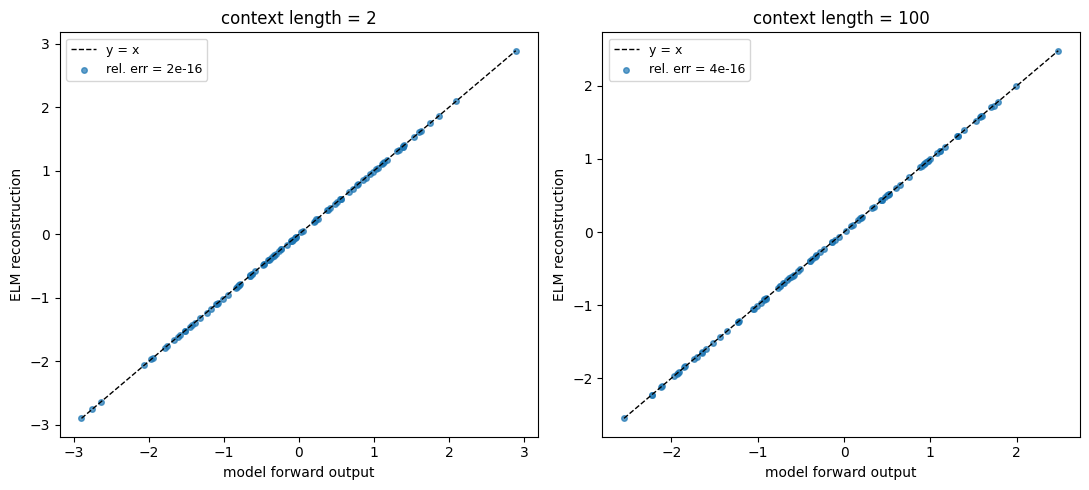

In [4]:
#| label: fig-elm-recon
#| fig-cap: "ELM reconstruction vs. model forward output for the last token, at context length 2 and 100. Points on the identity line (relative error ~1e-9) confirm the detached Jacobian is an exact linear decomposition of the model."
#| code-fold: true
from analysis.elm import reconstruction_scatter

mv_2,   ev_2   = reconstruction_scatter(model_bs2,   2,   n_windows=50, seed=SEED)
mv_100, ev_100 = reconstruction_scatter(model_bs100, 100, n_windows=50, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, mv, ev, label in [(axes[0], mv_2,   ev_2,   'context length = 2'),
                          (axes[1], mv_100, ev_100, 'context length = 100')]:
    err = np.linalg.norm(ev - mv) / np.linalg.norm(mv)
    lo, hi = float(min(mv.min(), ev.min())), float(max(mv.max(), ev.max()))
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x')
    ax.scatter(mv, ev, s=16, c='tab:blue', alpha=0.7, label=f'rel. err = {err:.0e}')
    ax.set_xlabel('model forward output'); ax.set_ylabel('ELM reconstruction')
    ax.set_title(label); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()


## Two world models: the Newton–Kepler phase transition

We first confirm *what* each model has learned, following Liu et al.'s **linear-probing** approach: take a physical quantity of interest and ask whether it can be recovered from the hidden state by a single linear projection, reporting the best layer's $R^2$ ($R^2=1$ means the quantity is perfectly linearly encoded). The **Newtonian** targets are local — the gravitational force $\mathbf F = -\mathbf r/|\mathbf r|^3$ and its components $F_x, F_y$, computable from the current position alone. The **Keplerian** targets describe the whole orbit: the semi-major and semi-minor axes $a, b$ (its size and shape), and the Laplace–Runge–Lenz vector $\mathbf A = (A_x, A_y)$, which points along the major axis toward perihelion and so encodes the orbit's orientation and eccentricity.

@fig-phase-transition shows the result. At **context length 2** the model linearly encodes the force variables; at **context length 100** it instead encodes the orbital-geometry variables. This is the phase transition Liu et al. identified, and our checkpoints reproduce it (consistent within run-to-run variance). The rest of the pub asks *how* the short-context model implements its Newtonian force.


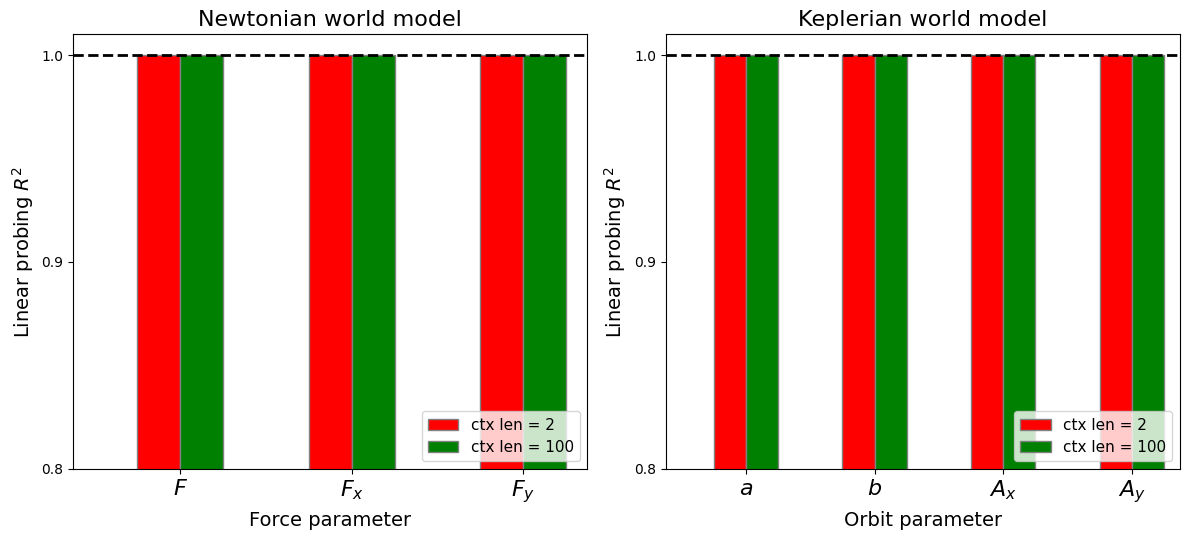

In [5]:
#| label: fig-phase-transition
#| fig-cap: "Best-layer, last-position linear-probing R² for Newtonian force variables (left) and Keplerian orbital parameters (right), at context length 2 vs 100. Short context encodes forces; long context encodes orbital geometry — consistent with Liu et al. within run-to-run variance."
#| code-fold: true
from analysis.data import load_trajectories, load_orbital_params
from analysis.probing import probe_model, best_r2

with contextlib.redirect_stdout(io.StringIO()):
    trajs    = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=NUM_TRAJ))
    o_params = load_orbital_params(DATA_DIR, num_trajectories_needed=NUM_TRAJ)
    newton_2,   kepler_2   = probe_model(model_bs2,   trajs, o_params, 2,   n_probe=100, seed=SEED)
    newton_100, kepler_100 = probe_model(model_bs100, trajs, o_params, 100, n_probe=100, seed=SEED)

NEWTON = [('F_magnitude', r'$F$'), ('Fx', r'$F_x$'), ('Fy', r'$F_y$')]
KEPLER = [('a', r'$a$'), ('b', r'$b$'), ('LRL_x', r'$A_x$'), ('LRL_y', r'$A_y$')]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, xlabel, items, p2, p100) in zip(axes, [
        ('Newtonian world model', 'Force parameter', NEWTON, newton_2, newton_100),
        ('Keplerian world model', 'Orbit parameter', KEPLER, kepler_2, kepler_100)]):
    targets = [t for t, _ in items]; ticklab = [l for _, l in items]
    r2_2   = [best_r2(p2,   t) for t in targets]
    r2_100 = [best_r2(p100, t) for t in targets]
    bw = 0.25; br1 = np.arange(len(targets))
    b1 = ax.bar(br1,      r2_2,   bw, color='r', edgecolor='grey', label='ctx len = 2')
    b2 = ax.bar(br1 + bw, r2_100, bw, color='g', edgecolor='grey', label='ctx len = 100')
    ax.plot([-0.5, len(targets) - 0.5], [1, 1], '--', color='black', lw=2)
    ax.set_xlim(-0.5, len(targets) - 0.5); ax.set_ylim(0.8, 1.01); ax.set_yticks([0.8, 0.9, 1.0])
    ax.set_xticks(br1 + 0.5 * bw); ax.set_xticklabels(ticklab, fontsize=16)
    ax.set_xlabel(xlabel, fontsize=14); ax.set_ylabel(r'Linear probing $R^2$', fontsize=14)
    ax.set_title(title, fontsize=16); ax.legend(handles=[b1, b2], fontsize=11, loc='lower right')
fig.tight_layout(); plt.show()


## Inside the short-context model

The probes tell us the short-context (context length 2) model linearly encodes force variables — but *encoding* a quantity is not the same as *computing with* it. With ELM we can read out the actual computation: how the model turns the two positions it sees, $\mathbf r_{t-1}$ and $\mathbf r_t$, into its prediction $\hat{\mathbf r}_{t+1}$.

Our reference point is the textbook second-order integrator of gravity, **Störmer–Verlet**:
$$\hat{\mathbf r}_{t+1} = 2\,\mathbf r_t - \mathbf r_{t-1} - \Delta t^2\,\nabla\phi(\mathbf r_t).$$
The inertial part $2\mathbf r_t - \mathbf r_{t-1}$ is just constant-velocity coasting — rewriting it as $\mathbf r_t + (\mathbf r_t - \mathbf r_{t-1})$, it reads "current position plus the last step's displacement." The final term is the small gravitational nudge. So a genuine force integrator weights its two inputs by $(c_{\text{prev}}, c_{\text{recent}}) = (-1, 2)$ plus a force correction; we call $(-1, 2)$ the **Verlet point**.

We read those weights straight off the Jacobian. Each per-token block $J_s$ is $2\times2$; its *isotropic* part $c_s = \mathrm{tr}(J_s)/D$ (here $D=2$) is the scalar by which input position $s$ is uniformly scaled into the prediction. A Newtonian model should land near $(c_{\text{prev}}, c_{\text{recent}}) = (-1, 2)$.


In [6]:
#| code-fold: true
#| output: false
# Mechanistic analysis of the short-context (noise=0.1) model. Reuses the model and
# constants loaded in the intro setup; only adds the analysis helpers.
from analysis import elm as NT
from analysis.data import load_trajectories

model = model_bs2                 # the bs=2, noise=0.1 model from the intro

BLOCK_SIZE    = 2
N_WINDOWS     = 200               # Jacobian-based analyses (expensive)
N_WINDOWS_BEH = 4000              # behavioural analyses (cheap forward passes)
SPLIT  = 'test'
OFFSET = 0 if SPLIT == 'train' else NUM_TRAJ   # 50/50 train/test split, by trajectory

def load_split_trajectories(n, data_dir=DATA_DIR, offset=None):
    offset = OFFSET if offset is None else offset
    with contextlib.redirect_stdout(io.StringIO()):
        trajs = np.asarray(load_trajectories(data_dir, num_trajectories_needed=offset + n))
    return trajs[offset:offset + n]


In [7]:
#| code-fold: true
#| output: false
# Per-token Jacobian blocks over N_WINDOWS real-orbit windows (slow; ~1-2 min).
all_blocks, coeffs, recon_err_max = NT.collect(model, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]
D = all_blocks.shape[-1]


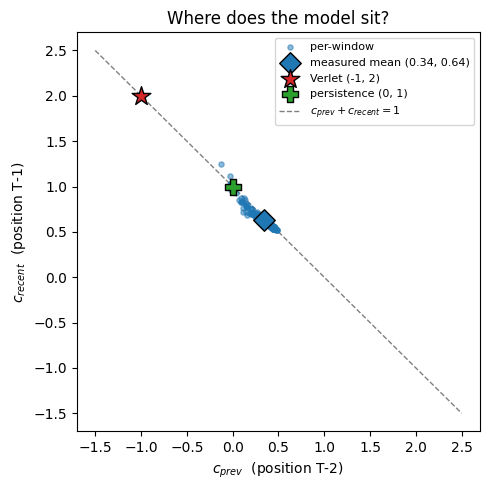

In [8]:
#| label: fig-verlet-coeff
#| fig-cap: "The noisy bs=2 model in (c_prev, c_recent) space, where c_s = tr(J_s)/D is each token's isotropic weight. Per-window points (blue) cluster near (0.36, 0.62) on the persistence line c_prev + c_recent = 1 — a weighted average of the two inputs — far from the Verlet point (-1, 2) that a forward-extrapolating integrator would occupy."
#| code-fold: true
positions = np.arange(T)
c_mean, c_std = coeffs.mean(0), coeffs.std(0)

target = np.zeros(T); target[T-1] = 2.0; target[T-2] = -1.0

fig, ax = plt.subplots(figsize=(5, 5))

c_prev, c_recent = coeffs[:, T-2], coeffs[:, T-1]
ax.scatter(c_prev, c_recent, s=14, alpha=0.5, color='tab:blue', label='per-window', zorder=2)
ax.scatter([c_prev.mean()], [c_recent.mean()], s=120, marker='D', color='tab:blue', edgecolor='k',
           label=f'measured mean ({c_prev.mean():.2f}, {c_recent.mean():.2f})', zorder=4)
ax.scatter([-1], [2], s=200, marker='*', color='tab:red', edgecolor='k', label='Verlet (-1, 2)', zorder=5)
ax.scatter([0], [1], s=120, marker='P', color='tab:green', edgecolor='k', label='persistence (0, 1)', zorder=4)
lo = min(-1.5, float(c_prev.min())); hi = max(2.5, float(c_recent.max()))
xs = np.linspace(lo, hi, 50)
ax.plot(xs, 1 - xs, ls='--', color='gray', lw=1, label=r'$c_{prev}+c_{recent}=1$', zorder=1)
ax.set_xlabel(r'$c_{prev}$  (position T-2)')
ax.set_ylabel(r'$c_{recent}$  (position T-1)')
ax.set_title('Where does the model sit?')
ax.legend(fontsize=8, loc='best')

fig.tight_layout()
plt.show()


@fig-verlet-coeff shows the model does **not** sit at the Verlet point. Its isotropic coefficients are $(c_{\text{prev}}, c_{\text{recent}}) \approx (0.36, 0.62)$ — they sum to $\approx 1$ but land nowhere near $(-1, 2)$. The dashed line $c_{\text{prev}} + c_{\text{recent}} = 1$ is the **persistence** line: any point on it passes a *static* input (two identical positions) through unchanged. A force integrator instead *extrapolates forward* along the velocity (overshooting $\mathbf r_t$, hence the weights $2, -1$ that sum to 1 but sit far out). The noisy model's two *positive* weights make its prediction a weighted **average** of its inputs — it interpolates, it does not extrapolate. So it is not doing textbook Newtonian integration.

What it *is* doing is clearer from the whole Jacobian block, not just its scale. @fig-jacobian-rotation shows the averaged per-token blocks: both are, to a good approximation, **scaled rotation matrices** — equal diagonals and equal-and-opposite off-diagonals, i.e. $J_s \approx c_s\,R(\theta_s)$ (a uniform scale composed with a turn by angle $\theta_s$). The model does not push $\mathbf r_t$ forward; it *turns* it.


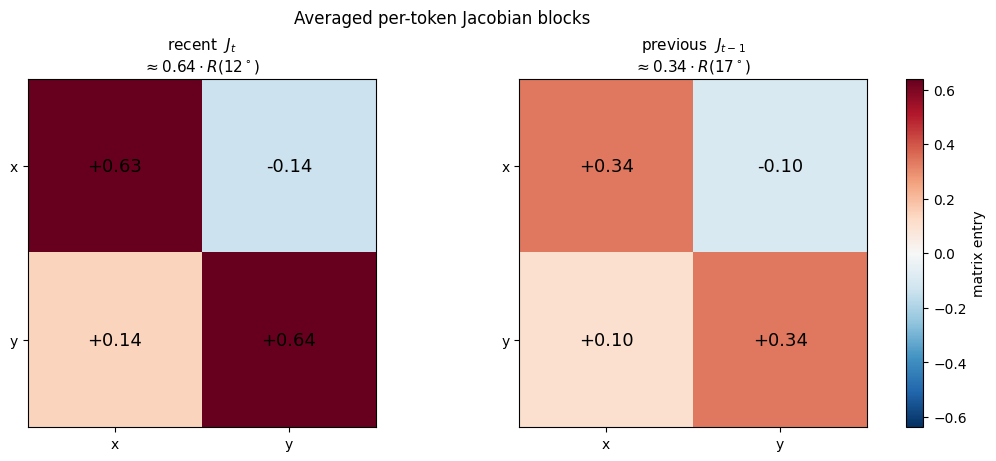

In [9]:
#| label: fig-jacobian-rotation
#| fig-cap: "Averaged per-token Jacobian blocks of the noisy bs=2 model. Both mean blocks are scaled rotation matrices (equal diagonals, equal-and-opposite off-diagonals), i.e. J ~ scale * R(angle) as annotated: a uniform scale composed with a small turn, rather than a forward push."
#| code-fold: true
from analysis.elm import rotation_decompose

mean_recent = all_blocks[:, T-1].mean(0)
mean_prev   = all_blocks[:, T-2].mean(0)
ds_r, a_r, ang_r, score_r = rotation_decompose(all_blocks[:, T-1])
ds_p, a_p, ang_p, score_p = rotation_decompose(all_blocks[:, T-2])
w_r    = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
radius = np.linalg.norm(w_r[:, T-1, :], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

vmax = max(abs(mean_recent).max(), abs(mean_prev).max())
sc_r, _, angm_r, _ = rotation_decompose(mean_recent)
sc_p, _, angm_p, _ = rotation_decompose(mean_prev)

for ax, M, name, sc, ang in [
    (axes[0], mean_recent, r'recent  $J_t$',       sc_r, angm_r),
    (axes[1], mean_prev,   r'previous  $J_{t-1}$', sc_p, angm_p)
]:
    im = ax.imshow(M, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['x', 'y']); ax.set_yticklabels(['x', 'y'])
    ax.set_title(f'{name}\n' +
                 rf'$\approx {float(sc):.2f}\cdot R({float(ang):.0f}^\circ)$',
                 fontsize=11)

fig.colorbar(im, ax=axes.tolist(), fraction=0.046, pad=0.04, label='matrix entry')
fig.suptitle('Averaged per-token Jacobian blocks', fontsize=12)
plt.show()

@fig-jacobian-rotation confirms it at the operator level: both averaged blocks are scaled rotations, $J \approx c\,R(\theta)$ — a uniform scale composed with a turn. But an *average* of matrices can look like a rotation even when the individual blocks do not, and it leaves open which way, and how strongly, each token is turned. @fig-rotation-generators checks both.

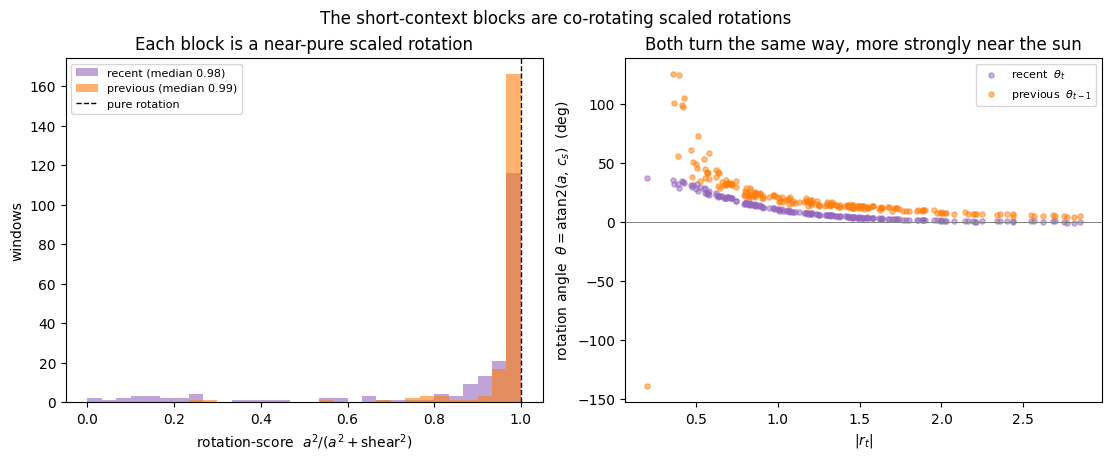

In [10]:
#| label: fig-rotation-generators
#| fig-cap: "Per-window rotation structure of the noisy bs=2 blocks. Left: the rotation-score a^2/(a^2 + shear^2 + diag^2) is near 1 for both tokens, so each individual block (not just the average) is a near-pure scaled rotation (shear negligible). Right: the implied rotation angle theta = atan2(a, c_s) - scale-free, unlike the raw generator - is positive for both tokens (they co-rotate) and grows as the planet nears the sun."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

# Left — rotation score histogram
ax = axes[0]
ax.hist(score_r, bins=30, range=(0, 1), color='tab:purple', alpha=0.6,
        label=f'recent (median {np.median(score_r):.2f})')
ax.hist(score_p, bins=30, range=(0, 1), color='tab:orange', alpha=0.6,
        label=f'previous (median {np.median(score_p):.2f})')
ax.axvline(1, color='k', ls='--', lw=1, label='pure rotation')
ax.set_xlabel(r'rotation-score  $a^2/(a^2+\mathrm{shear}^2)$')
ax.set_ylabel('windows')
ax.set_title('Each block is a near-pure scaled rotation')
ax.legend(fontsize=8, loc='upper left')

# Right — rotation ANGLE theta = atan2(a, c_s), scale-free, vs radius
ax = axes[1]
ax.axhline(0, color='gray', lw=0.7)
ax.scatter(radius, ang_r, s=14, alpha=0.5, color='tab:purple', label=r'recent  $\theta_t$')
ax.scatter(radius, ang_p, s=14, alpha=0.5, color='tab:orange', label=r'previous  $\theta_{t-1}$')
ax.set_xlabel(r'$|r_t|$')
ax.set_ylabel(r'rotation angle  $\theta=\operatorname{atan2}(a,\,c_s)$  (deg)')
ax.set_title('Both turn the same way, more strongly near the sun')
ax.legend(fontsize=8)

fig.suptitle('The short-context blocks are co-rotating scaled rotations', fontsize=12)
plt.show()

A $2\times2$ block splits into an isotropic part $c_s = \tfrac12\operatorname{tr}J$ (equal diagonal) and a **rotation generator** $a = \tfrac12(J_{21} - J_{12})$ (antisymmetric off-diagonal). These are not "scale" and "turn" on their own: a rotation's diagonal is $\cos\theta$, so a pure turn *hides* in $c_s$, and in fact $c_s = \text{scale}\cdot\cos\theta$ and $a = \text{scale}\cdot\sin\theta$. We therefore read the pair *jointly*, as a single scaled rotation — its **scale** is the magnitude $\sqrt{c_s^2 + a^2}$ and its **turn** is the angle $\theta = \operatorname{atan2}(a, c_s)$.

@fig-rotation-generators (left) shows the rotation-score $a^2/(a^2+\text{shear}^2)$ — where $\text{shear}^2$ is the full symmetric-traceless distortion (unequal diagonals plus symmetric off-diagonal), and the isotropic scale is deliberately *not* in the ratio, which asks only whether the *direction-changing* action is a turn or a distortion — sits near 1 for *both* tokens. So each block is a near-pure **scaled rotation** (shear $\approx 0$), not a shear or reflection, and the averaged picture in @fig-jacobian-rotation is not a pooling artifact. (right) The angle $\theta$ is *positive for both tokens* (they co-rotate) and *grows as the planet nears the sun*.

Per block the turn is modest ($\theta \approx 10$–$15^\circ$) on top of a real contraction (scale $\approx 0.63$ recent, $0.37$ previous — well below 1, so genuine averaging weights, not a rotation artifact). Their sum lands on the persistence line of @fig-verlet-coeff, so the *combined* operator $J_t + J_{t-1}$, applied to $\mathbf r_t$, is a near-unit-scale rotation (scale $\approx 1.0$, turn $\approx 9^\circ$). Because the two blocks act on *different* positions — $\mathbf r_{t-1}$ trails $\mathbf r_t$ by $\sim\!12\%$ of a radius each step — this is an operator-level statement, not yet a behavioral one; the model's actual predictions confirm it directly ($|\hat{\mathbf y}| \approx |\mathbf r_t|$), which is exactly what @fig-kepler2 measures next. Either way the picture is a circular-orbit step: hold $|\mathbf r|$, rotate — the scaling does the averaging, the rotation supplies the advance.

### What the rotation depends on

The model *turns* $\mathbf r_t$ — but what sets the angle? Kepler's second law (a planet sweeps equal areas in equal times) fixes the per-step angle of a real orbit to $\Delta\theta = L_z\,\Delta t / r^2$, where $L_z = x\,\dot y - y\,\dot x$ is the **angular momentum** — the conserved rate at which the position vector sweeps out area. So the true angle grows like $1/r^2$ (faster near the sun) *and* scales with $L_z$ (which differs from orbit to orbit). We compare the model's per-step rotation against both, and against the radial in-and-out motion a real orbit undergoes.


In [11]:
#| code-fold: true
#| output: false
# Behavioural rotation statistics over many cheap forward passes.
behav = NT.rotation_behavioral(model, BLOCK_SIZE, N_WINDOWS_BEH, seed=SEED, offset=OFFSET)


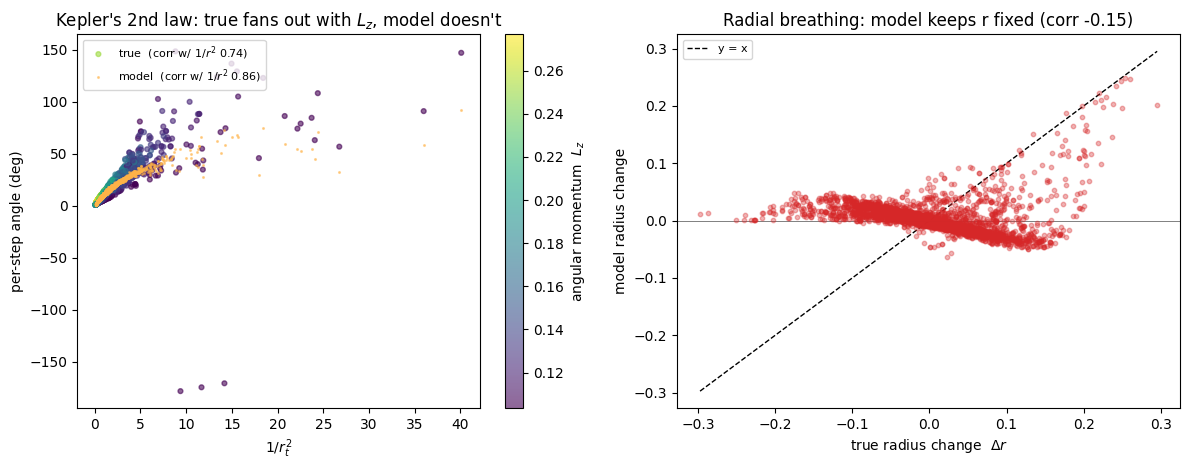

In [12]:
#| label: fig-kepler2
#| fig-cap: "Left: per-step rotation angle vs 1/r^2. The true orbit's angle (coloured by angular momentum L_z) fans out with L_z per Kepler's 2nd law, whereas the model's angle (orange) is a tight function of 1/r^2 alone — it ignores L_z. Right: the true per-step radius change vs the model's; the model keeps the radius almost fixed, ignoring the orbit's radial breathing."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left — Kepler's 2nd law: per-step angle vs 1/r^2
ax = axes[0]
Lz, inv_r2 = behav['Lz'], behav['inv_r2']
at, am = np.degrees(behav['ang_true']), np.degrees(behav['ang_model'])
vlo, vhi = float(np.nanpercentile(Lz, 2)), float(np.nanpercentile(Lz, 98))
sc = ax.scatter(inv_r2, at, s=12, alpha=0.6, c=Lz, cmap='viridis', vmin=vlo, vmax=vhi,
                label=f"true  (corr w/ $1/r^2$ {behav['kepler2_corr_true']:.2f})")
ax.scatter(inv_r2, am, s=6, alpha=0.5, color='#FFB347', marker='.',
           label=f"model  (corr w/ $1/r^2$ {behav['kepler2_corr_model']:.2f})")
cb = fig.colorbar(sc, ax=ax); cb.set_label(r'angular momentum  $L_z$')
ax.set_xlabel(r'$1/r_t^2$'); ax.set_ylabel('per-step angle (deg)')
ax.set_title(r"Kepler's 2nd law: true fans out with $L_z$, model doesn't")
ax.legend(fontsize=8, loc='upper left')

# Right — radial breathing
ax = axes[1]
dtr, dmr = behav['dr_true'], behav['dr_model']
lo, hi = float(min(dtr.min(), dmr.min())), float(max(dtr.max(), dmr.max()))
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.axhline(0, color='gray', lw=0.7, zorder=1)
ax.scatter(dtr, dmr, s=10, alpha=0.35, color='tab:red', zorder=2)
ax.set_xlabel(r'true radius change  $\Delta r$'); ax.set_ylabel(r'model radius change')
ax.set_title(f"Radial breathing: model keeps r fixed (corr {behav['dr_corr']:.2f})")
ax.legend(fontsize=8)

fig.tight_layout(); plt.show()


Two things stand out in @fig-kepler2. The model's rotation angle **does** grow like $1/r^2$ — it speeds up near the sun — but unlike the true orbit it is a *single tight curve*: it **ignores angular momentum** (the orange points show no vertical spread, while the true points fan out by colour). And on the right, the model barely changes the radius step-to-step — it **ignores the orbit's radial breathing**, keeping the planet on a circle.

Together these say the model isn't tracking the real orbit; it treats each step as if the planet were on a *local circular orbit* of the current radius. A circular orbit at radius $r$ sweeps $\Delta\theta = \Delta t / r^{3/2}$ per step (with $GM=1$). If that is the heuristic, the model's rotation should match this curve:


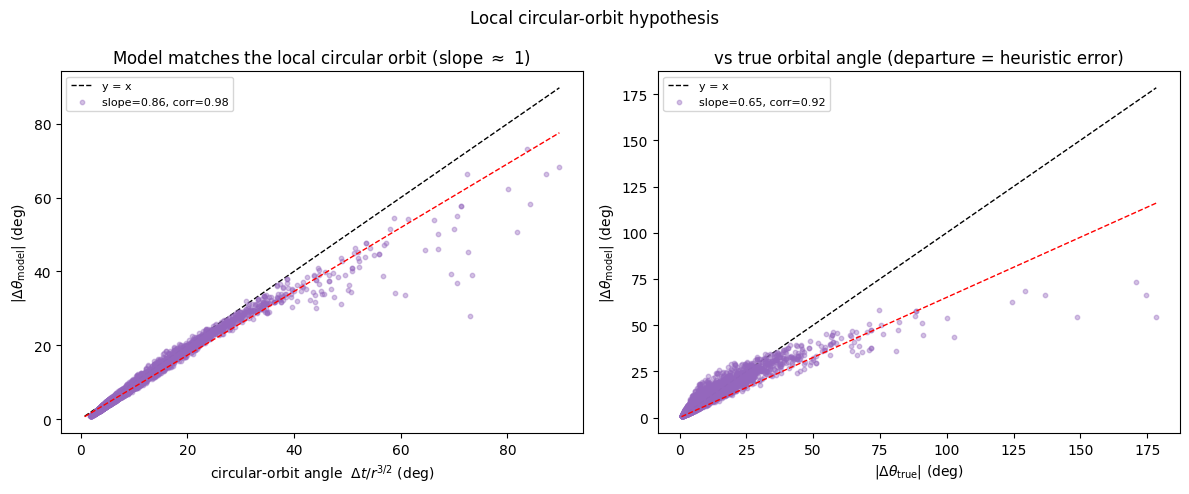

In [13]:
#| label: fig-circular
#| fig-cap: "Left: model per-step rotation angle vs the angle a circular orbit of the same radius sweeps (dt / r^{3/2}); slope ~ 1 shows the model applies the local-circular-orbit rotation. Right: model angle vs the true orbital angle; departures from y=x are the heuristic's error on eccentric orbits. (Windows with a circular prediction > 90 deg are dropped.)"
#| code-fold: true
DT = 0.2
r_t          = behav['inv_r2'] ** (-0.5)
ang_circular = np.degrees(DT / r_t**1.5)
am_abs, at_abs = np.abs(np.degrees(behav['ang_model'])), np.abs(np.degrees(behav['ang_true']))

mask = ang_circular < 90.0
ang_c_m, am_m, at_m = ang_circular[mask], am_abs[mask], at_abs[mask]
corr_m,   slope_m   = np.corrcoef(ang_c_m, am_m)[0, 1], np.polyfit(ang_c_m, am_m, 1)[0]
corr_beh, slope_beh = np.corrcoef(at_m,   am_m)[0, 1], np.polyfit(at_m,   am_m, 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
lo, hi = float(min(ang_c_m.min(), am_m.min())), float(max(ang_c_m.max(), am_m.max()))
xs = np.linspace(lo, hi, 100)
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(ang_c_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'slope={slope_m:.2f}, corr={corr_m:.2f}')
ax.plot(xs, slope_m * xs, 'r--', lw=1)
ax.set_xlabel(r'circular-orbit angle  $\Delta t / r^{3/2}$ (deg)')
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)')
ax.set_title(r'Model matches the local circular orbit (slope $\approx$ 1)')
ax.legend(fontsize=8)

ax = axes[1]
lo2, hi2 = float(min(at_m.min(), am_m.min())), float(max(at_m.max(), am_m.max()))
xs2 = np.linspace(lo2, hi2, 100)
ax.plot([lo2, hi2], [lo2, hi2], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(at_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'slope={slope_beh:.2f}, corr={corr_beh:.2f}')
ax.plot(xs2, slope_beh * xs2, 'r--', lw=1)
ax.set_xlabel(r'$|\Delta\theta_{\rm true}|$ (deg)')
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)')
ax.set_title('vs true orbital angle (departure = heuristic error)')
ax.legend(fontsize=8)

fig.suptitle('Local circular-orbit hypothesis', fontsize=12)
fig.tight_layout(); plt.show()


### The noisy short-context model runs a local circular-orbit heuristic

@fig-circular confirms it: the model's rotation angle tracks the circular-orbit prediction $\Delta t / r^{3/2}$ with slope $\approx 1$ (left), and departs from the *true* angle only where real orbits deviate from circular (right).

So the noise-robust short-context model has **not** learned Newtonian gravity. It has learned a **local circular-orbit heuristic**: rotate the most recent position by the angle a circular orbit of that radius would sweep, and hold the radius fixed. This is a smooth, noise-tolerant approximation — it captures the $1/r^2$ angular speed-up but discards angular momentum and radial dynamics, which is exactly why it degrades on eccentric orbits. The genuine Newtonian mechanism only emerges once we remove the training noise — the subject of the next section.


## Without training noise, the model learns Newton

The noisy short-context model settled for a smooth, noise-robust heuristic. Does the *mechanism* change when we remove the training noise? We repeat the analysis on the **noiseless** bs=2 model (`noise_scale = 0.0`). Freed from having to tolerate corrupted context, it can afford the sharp finite-difference computation of a genuine force integrator — and the ELM decomposition shows it does exactly that.


In [14]:
#| code-fold: true
#| output: false
# Switch to the NOISELESS model (noise_scale = 0.0) and recompute its Jacobian blocks.
CKPT_BS2_NL = f'{CHECKPOINT_DIR}/model_block_size_{BLOCK_SIZE}_num_trajectories_{NUM_TRAJ}_noise_scale_0.0.pt'
with contextlib.redirect_stdout(io.StringIO()):
    model_noiseless, _ = load_from_checkpoint(CKPT_BS2_NL, device='cpu'); model_noiseless.eval()
    all_blocks, coeffs, recon_err_max = NT.collect(model_noiseless, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]; D = all_blocks.shape[-1]


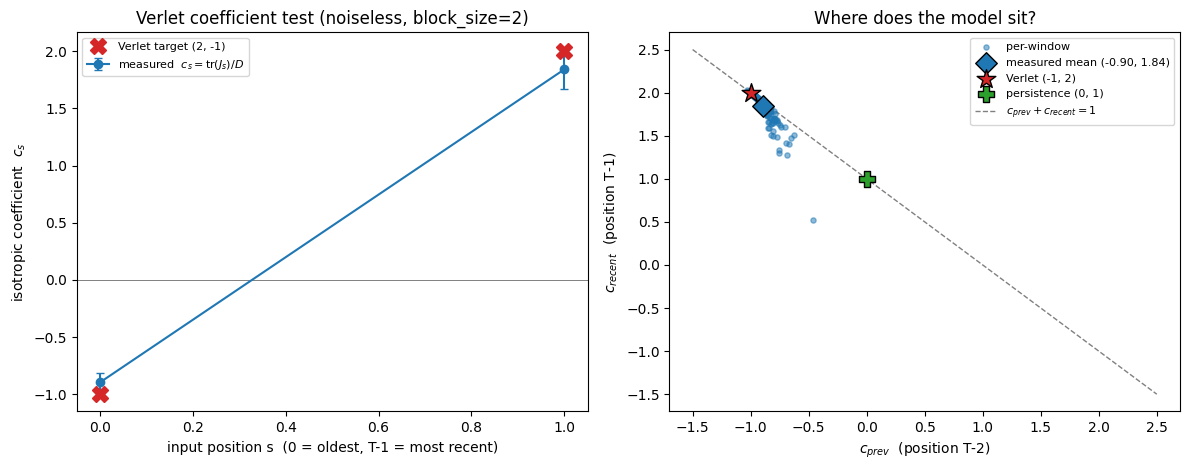

In [15]:
#| label: fig-verlet-noiseless
#| fig-cap: "Isotropic Jacobian coefficients of the noiseless bs=2 model. Unlike the noisy model, the measured mean (c_prev, c_recent) ~ (-0.9, 1.85) sits essentially on the Verlet point (-1, 2): the noiseless model is a second-order (Verlet) integrator."
#| code-fold: true
positions = np.arange(T)
c_mean, c_std = coeffs.mean(0), coeffs.std(0)

target = np.zeros(T); target[T-1] = 2.0; target[T-2] = -1.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
ax.axhline(0, color='gray', lw=0.7)
ax.errorbar(positions, c_mean, yerr=c_std, fmt='-o', color='tab:blue', capsize=3,
            label=r'measured  $c_s=\mathrm{tr}(J_s)/D$')
ax.plot(positions, target, 'X', color='tab:red', ms=12, label='Verlet target (2, -1)')
ax.set_xlabel('input position s  (0 = oldest, T-1 = most recent)')
ax.set_ylabel(r'isotropic coefficient  $c_s$')
ax.set_title(f'Verlet coefficient test (noiseless, block_size={BLOCK_SIZE})'); ax.legend(fontsize=8)

ax = axes[1]
c_prev, c_recent = coeffs[:, T-2], coeffs[:, T-1]
ax.scatter(c_prev, c_recent, s=14, alpha=0.5, color='tab:blue', label='per-window', zorder=2)
ax.scatter([c_prev.mean()], [c_recent.mean()], s=120, marker='D', color='tab:blue', edgecolor='k',
           label=f'measured mean ({c_prev.mean():.2f}, {c_recent.mean():.2f})', zorder=4)
ax.scatter([-1], [2], s=200, marker='*', color='tab:red', edgecolor='k', label='Verlet (-1, 2)', zorder=5)
ax.scatter([0], [1], s=120, marker='P', color='tab:green', edgecolor='k', label='persistence (0, 1)', zorder=4)
lo = min(-1.5, float(c_prev.min())); hi = max(2.5, float(c_recent.max()))
xs = np.linspace(lo, hi, 50)
ax.plot(xs, 1 - xs, ls='--', color='gray', lw=1, label=r'$c_{prev}+c_{recent}=1$', zorder=1)
ax.set_xlabel(r'$c_{prev}$  (position T-2)'); ax.set_ylabel(r'$c_{recent}$  (position T-1)')
ax.set_title('Where does the model sit?'); ax.legend(fontsize=8, loc='best')

fig.tight_layout(); plt.show()


The contrast with the noisy model is stark. @fig-verlet-noiseless shows the noiseless model's isotropic coefficients at $(c_{\text{prev}}, c_{\text{recent}}) \approx (-0.9, +1.85)$ — essentially **on the Verlet point** $(-1, 2)$, not the persistence line the noisy model occupied at $(0.36, 0.62)$. This model *extrapolates forward* like a genuine second-order integrator, $\hat{\mathbf r}_{t+1} \approx 2\mathbf r_t - \mathbf r_{t-1} + (\text{correction})$, rather than blending its two inputs.


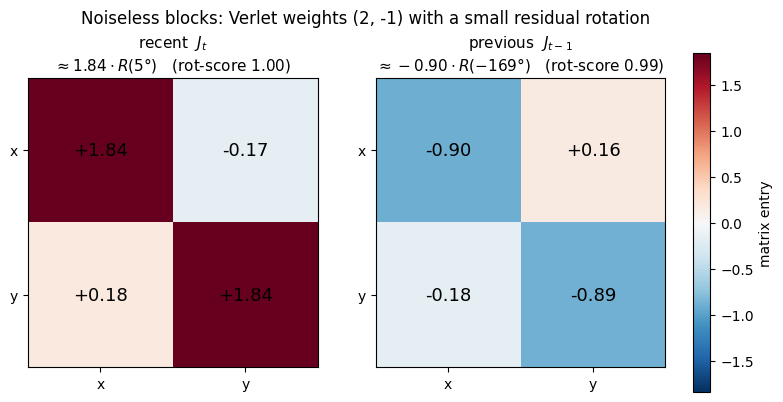

In [15]:
#| label: fig-jacobian-rotation-noiseless
#| fig-cap: "Averaged per-token Jacobian blocks of the noiseless bs=2 model: J_recent ~ 1.85 R(5 deg), J_prev ~ -0.9 R(...). These are the Verlet weights (2, -1) carrying only a small residual rotation - the leading-order behaviour is inertial extrapolation, not the large rotation of the noisy model."
#| code-fold: true
from analysis.elm import rotation_decompose

mean_recent = all_blocks[:, T-1].mean(0)
mean_prev   = all_blocks[:, T-2].mean(0)
_, _, _, score_recent = rotation_decompose(all_blocks[:, T-1])
_, _, _, score_prev   = rotation_decompose(all_blocks[:, T-2])
sc_r, _, ang_r, _ = rotation_decompose(mean_recent)
sc_p, _, ang_p, _ = rotation_decompose(mean_prev)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
vmax = max(abs(mean_recent).max(), abs(mean_prev).max())
for ax, M, name, sc, ang, sco in [
        (axes[0], mean_recent, r'recent  $J_{t}$',     sc_r, ang_r, score_recent.mean()),
        (axes[1], mean_prev,   r'previous  $J_{t-1}$', sc_p, ang_p, score_prev.mean())]:
    im = ax.imshow(M, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['x', 'y']); ax.set_yticklabels(['x', 'y'])
    ax.set_title(f'{name}\n' + rf'$\approx {float(sc):.2f}\cdot R({float(ang):.0f}\degree)$   (rot-score {sco:.2f})', fontsize=11)
fig.colorbar(im, ax=list(axes), fraction=0.046, pad=0.04, label='matrix entry')
fig.suptitle('Noiseless blocks: Verlet weights (2, -1) with a small residual rotation', fontsize=12)
plt.show()


So the noiseless model is, to leading order, a **Verlet integrator**: it reproduces the inertial weights $(2, -1)$ (@fig-verlet-noiseless), and its Jacobian blocks are those weights carrying only a small residual rotation (@fig-jacobian-rotation-noiseless). The physics that makes it *Newtonian* rather than merely inertial lives in that residual — the deviation from the ideal Verlet weights, $\mathrm{d}J = J - (2I,\,-I)$. In the next step we decompose $\mathrm{d}J$ and show that this small correction is exactly the Newtonian gravitational kick $-\Delta t^2\,\mathbf r_t/|\mathbf r_t|^3$, assembled from the isotropic, rotation, and shear channels and trimmed to unit strength by the positional term.


### The deviation from Verlet is Newtonian gravity

That small residual is where the physics lives. Before decomposing it, we check *behaviourally* — with no reference to the Jacobian — whether the model's non-inertial output is actually Newtonian gravity. From the model's own second difference, $\mathbf a_{\rm eff} = (\hat{\mathbf r}_{t+1} - 2\mathbf r_t + \mathbf r_{t-1})/\Delta t^2$, a genuine force integrator would give $\mathbf a_{\rm eff} = -\mathbf r_t/|\mathbf r_t|^3$ ($GM=1$).


n=4000  (noiseless, SPLIT=test)
(1) direction cos(a_eff, -r_hat): median +0.999  mean +0.993
(2) |a_eff| ~ r^p:  p=-1.92 (Newtonian -2);  GM_est=1.040 (true 1.0)
(3) component corr:  x +0.977   y +0.980

  r-bin          n    cos(dir)   |a|*r^2
  [0.0, 0.9)   1129   +1.000     1.021
  [0.9, 1.2)    786   +1.000     1.048
  [1.2, 1.6)    962   +0.999     1.065
  [1.6, 2.2)    735   +0.998     1.085
  [2.2, inf)    388   +0.989     1.210


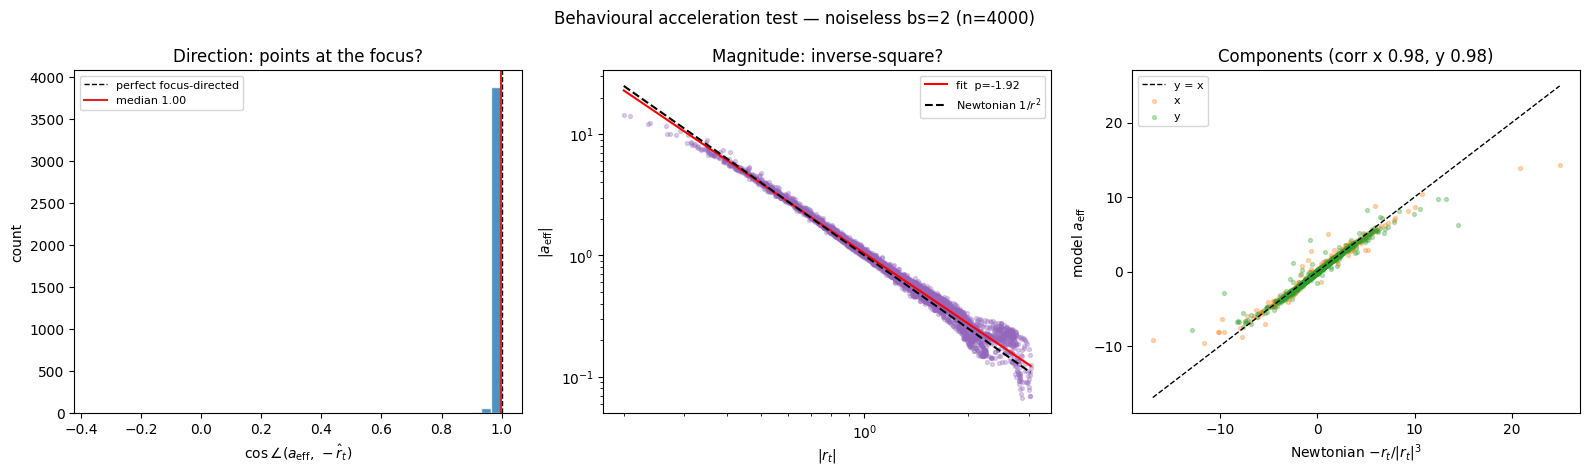

In [16]:
#| label: fig-newton-behavioral
#| fig-cap: "Attribution-free test that the noiseless model's non-inertial output is Newtonian gravity. a_eff = (r_hat - 2 r_t + r_prev)/dt^2. Left: a_eff points at the sun (cos ~ 0.999). Middle: |a_eff| ~ 1/r^1.9 (Newtonian -2), GM_est ~ 1.04. Right: components match -r_t/|r_t|^3 (corr ~ 0.98)."
#| code-fold: true
# ── Behavioural acceleration test: is the model's non-inertial output Newtonian gravity? ──
# Attribution-free — uses the second difference of the model's OWN prediction, so it's
# invariant to how gravity is split across J_recent / J_prev:
#   a_eff = (r_hat_{t+1} - 2 r_t + r_{t-1}) / dt^2     (Verlet: a_eff = -r_t/|r_t|^3, GM=1)
# Tests (1) does a_eff point at the focus?  (2) does |a_eff| ~ 1/r^2?
DT    = 0.2
N_ACC = 4000
mdl   = model_noiseless                      # the noiseless (Verlet-like) model

w = NT.sample_orbit_windows(BLOCK_SIZE, N_ACC, seed=SEED, offset=OFFSET)   # (n,2,2)
r_prev, r_t = w[:, -2, :], w[:, -1, :]

mdtype = next(mdl.parameters()).dtype
with torch.no_grad():
    pred = mdl(torch.tensor(w).to(mdtype))[0][:, -1, :].double().numpy()   # (n,2)

a_eff  = (pred - 2*r_t + r_prev) / DT**2      # model's effective acceleration
r      = np.linalg.norm(r_t, axis=1)
a_true = -r_t / r[:, None]**3                 # Newtonian gravity at r_t (GM=1)

# (1) direction: cos between measured and Newtonian (focus-directed) acceleration
cos_dir = (a_eff*a_true).sum(1) / (np.linalg.norm(a_eff,axis=1)*np.linalg.norm(a_true,axis=1) + 1e-30)
# (2) magnitude scaling: |a_eff| ~ r^p; Newtonian p=-2, intercept -> GM
mag = np.linalg.norm(a_eff, axis=1)
slope, intercept = np.polyfit(np.log(r), np.log(mag), 1)
GM_est = np.exp(intercept)
# (3) component-wise agreement
corr_x = np.corrcoef(a_eff[:,0], a_true[:,0])[0,1]
corr_y = np.corrcoef(a_eff[:,1], a_true[:,1])[0,1]

print(f"n={N_ACC}  (noiseless, SPLIT={SPLIT})")
print(f"(1) direction cos(a_eff, -r_hat): median {np.median(cos_dir):+.3f}  mean {cos_dir.mean():+.3f}")
print(f"(2) |a_eff| ~ r^p:  p={slope:+.2f} (Newtonian -2);  GM_est={GM_est:.3f} (true 1.0)")
print(f"(3) component corr:  x {corr_x:+.3f}   y {corr_y:+.3f}")

# gravity S/N is high at perihelion, low at aphelion (2nd difference amplifies pred noise)
print("\n  r-bin          n    cos(dir)   |a|*r^2")
for lo_, hi_ in [(0,0.9),(0.9,1.2),(1.2,1.6),(1.6,2.2),(2.2,np.inf)]:
    m = (r>=lo_) & (r<hi_)
    if m.sum():
        print(f"  [{lo_:.1f},{hi_:>4.1f})   {m.sum():>4d}   {np.median(cos_dir[m]):+.3f}     {np.median(mag[m]*r[m]**2):.3f}")

# ── figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax = axes[0]
ax.hist(cos_dir, bins=40, color='tab:blue', alpha=0.8, edgecolor='white')
ax.axvline(1, color='k', ls='--', lw=1, label='perfect focus-directed')
ax.axvline(np.median(cos_dir), color='tab:red', lw=1.5, label=f'median {np.median(cos_dir):.2f}')
ax.set_xlabel(r'$\cos\angle(a_{\rm eff},\,-\hat r_t)$'); ax.set_ylabel('count')
ax.set_title('Direction: points at the focus?'); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(r, mag, s=8, alpha=0.3, color='tab:purple')
rr = np.linspace(r.min(), r.max(), 100)
ax.plot(rr, GM_est*rr**slope, 'r-',  lw=1.5, label=f'fit  p={slope:.2f}')
ax.plot(rr, rr**-2.0,         'k--', lw=1.5, label=r'Newtonian $1/r^2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$|r_t|$'); ax.set_ylabel(r'$|a_{\rm eff}|$')
ax.set_title('Magnitude: inverse-square?'); ax.legend(fontsize=8)

ax = axes[2]
lo = float(min(a_eff.min(), a_true.min())); hi = float(max(a_eff.max(), a_true.max()))
ax.plot([lo,hi],[lo,hi],'k--',lw=1,label='y = x')
ax.scatter(a_true[:,0], a_eff[:,0], s=8, alpha=0.3, color='tab:orange', label='x')
ax.scatter(a_true[:,1], a_eff[:,1], s=8, alpha=0.3, color='tab:green',  label='y')
ax.set_xlabel(r'Newtonian $-r_t/|r_t|^3$'); ax.set_ylabel(r'model $a_{\rm eff}$')
ax.set_title(f'Components (corr x {corr_x:.2f}, y {corr_y:.2f})'); ax.legend(fontsize=8)

fig.suptitle(f'Behavioural acceleration test — noiseless bs={BLOCK_SIZE} (n={N_ACC})', fontsize=12)
fig.tight_layout(); plt.show()

@fig-newton-behavioral confirms it: the model's effective acceleration **points at the sun** ($\cos \approx 0.999$), **scales inverse-square** ($|\mathbf a_{\rm eff}| \sim r^{-1.9}$ vs. Newtonian $r^{-2}$) with the right strength ($GM_{\rm est}\approx 1.04$), and matches gravity component-by-component ($\mathrm{corr}\approx 0.98$). Unlike the noisy model's circular heuristic, the noiseless model has learned the true $1/r^2$ force. Now we open up *how* the Jacobian assembles it.


### How the force is built: three channels of the Jacobian

To see *how* the kick is assembled we work with the **deviation from the ideal Verlet weights**, $\mathrm{d}J_s = J_s - J_s^{\text{Verlet}}$ (with $J^{\text{Verlet}}_{\text{recent}}=2I$ and $J^{\text{Verlet}}_{\text{prev}}=-I$). The model's non-inertial correction is $\mathrm{d}J_{\text{recent}}\,\mathbf r_t + \mathrm{d}J_{\text{prev}}\,\mathbf r_{t-1}$, which — by the behavioural test above — must equal the gravity kick $-\Delta t^2\,\mathbf r_t/|\mathbf r_t|^3$.

Each $\mathrm{d}J_s$ is a $2\times2$ linear map, and any such map splits into three geometrically distinct channels:

$$\mathrm{d}J \;=\; \underbrace{d_s\,I}_{\text{isotropic (dilation)}} \;+\; \underbrace{a\,R}_{\text{rotation}} \;+\; \underbrace{G}_{\text{shear}}, \qquad R=\begin{pmatrix}0&-1\\1&0\end{pmatrix},$$

where $d_s=\tfrac12\operatorname{tr}(\mathrm{d}J)$ scales the vector uniformly, $a=\tfrac12(\mathrm{d}J_{21}-\mathrm{d}J_{12})$ rotates it, and the symmetric-traceless remainder $G$ shears it. @fig-kick-decomposition asks two questions: **which channel supplies the inward, gravity-aligned kick**, and **how does each channel's coefficient scale with radius** — a genuine $1/r^2$ force needs coefficients that grow as the planet nears the sun.


decomposition closes (iso+rot+sym == dJ@r): True

component         cos(·,grav)   frac of grav   median|·|
  isotropic         +0.855        +0.79         0.0272
  rotation          +0.886        +0.86         0.0318
  sym-traceless     +0.250        +0.03         0.0175
  TOTAL dJ@r        +0.972        +1.57         0.0560
  gravity kick      +1.000        +1.00         0.0268

── rotation coefficient scaling: (a) constant vs (b) ~1/r^2 ──
  a_recent: mean +0.176  |a|~r^-0.50  corr(|a|,1/r^2)=+0.81
  a_prev: mean -0.170  |a|~r^-0.54  corr(|a|,1/r^2)=+0.93


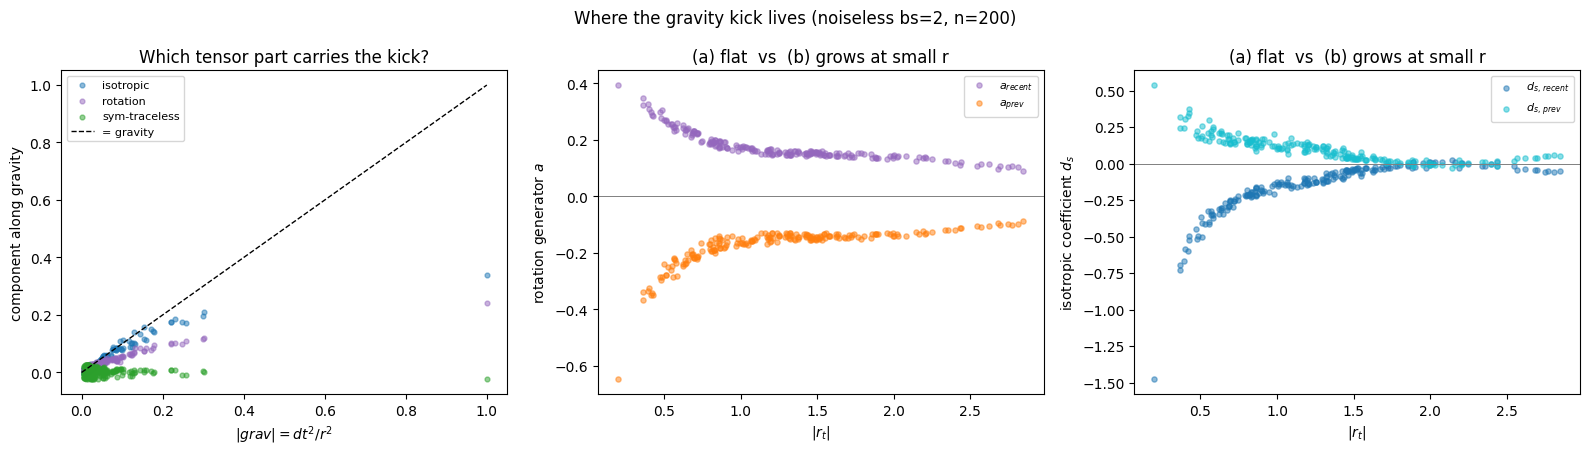

In [17]:
#| label: fig-kick-decomposition
#| fig-cap: "Decomposition of the Verlet-deviation dJ@r into isotropic / rotation / shear channels. Left: isotropic and rotation carry the gravity-aligned kick, shear ~ 0. Middle/right: the rotation and isotropic coefficients grow toward small r, supplying the inverse-square scaling."
#| code-fold: true
# ── Where does the Verlet gravity kick live? Decompose the non-inertial output ──
# non-inertial content = dJ_rec @ r_t + dJ_prev @ r_{t-1},  dJ = J - Verlet ideal.
# A 2x2 dJ has 4 dof: isotropic (ds·I) + rotation (a·R) + symmetric-traceless (G).
# Question: which part supplies the kick  grav = -dt^2 r_t/|r_t|^3, and does the
# rotation coefficient a stay constant (a) or scale with gravity ~1/r^2 (b)?
R = np.array([[0.,-1.],[1.,0.]]); I2 = np.eye(2); DT = 0.2

w_j = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)  # matches all_blocks
r_t, r_pr = w_j[:, -1, :], w_j[:, -2, :]
r    = np.linalg.norm(r_t, axis=1); v = r_t - r_pr
grav = -DT**2 * r_t / r[:, None]**3

Jr = all_blocks[:, T-1] - 2*I2      # dJ_recent
Jp = all_blocks[:, T-2] + 1*I2      # dJ_prev

def parts(J):
    ds  = (J[:,0,0] + J[:,1,1]) / 2                              # isotropic scalar
    a   = (J[:,1,0] - J[:,0,1]) / 2                              # rotation scalar
    sym = (J + J.transpose(0,2,1)) / 2
    G   = sym - ((sym[:,0,0]+sym[:,1,1])/2)[:,None,None]*I2      # symmetric-traceless
    return ds, a, G

ds_r, a_r, G_r = parts(Jr); ds_p, a_p, G_p = parts(Jp)
mv = lambda M, x: np.einsum('nij,nj->ni', M, x)

iso = ds_r[:,None]*r_t + ds_p[:,None]*r_pr
rot = (a_r[:,None]*r_t + a_p[:,None]*r_pr) @ R.T
sym = mv(G_r, r_t) + mv(G_p, r_pr)
recon = mv(Jr, r_t) + mv(Jp, r_pr)                              # full non-inertial content
print("decomposition closes (iso+rot+sym == dJ@r):", np.allclose(iso+rot+sym, recon))

cyl  = lambda u, w: (u*w).sum(1)/(np.linalg.norm(u,axis=1)*np.linalg.norm(w,axis=1)+1e-30)
frac = lambda u: np.median((u*grav).sum(1)/(grav*grav).sum(1))
print("\ncomponent         cos(·,grav)   frac of grav   median|·|")
for name, u in [('isotropic',iso),('rotation',rot),('sym-traceless',sym),
                ('TOTAL dJ@r',recon),('gravity kick',grav)]:
    print(f"  {name:14s}    {np.median(cyl(u,grav)):+.3f}        {frac(u):+.2f}         {np.median(np.linalg.norm(u,axis=1)):.4f}")

print("\n── rotation coefficient scaling: (a) constant vs (b) ~1/r^2 ──")
for name, a in [('a_recent',a_r),('a_prev',a_p)]:
    print(f"  {name}: mean {a.mean():+.3f}  |a|~r^{np.polyfit(np.log(r),np.log(np.abs(a)),1)[0]:+.2f}"
          f"  corr(|a|,1/r^2)={np.corrcoef(np.abs(a),1/r**2)[0,1]:+.2f}")

# ── figure ──
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
gmag = np.linalg.norm(grav, axis=1)
ax = axes[0]
for u,c,l in [(iso,'tab:blue','isotropic'),(rot,'tab:purple','rotation'),(sym,'tab:green','sym-traceless')]:
    ax.scatter(gmag, (u*grav).sum(1)/gmag, s=12, alpha=0.5, color=c, label=l)
ax.plot([0,gmag.max()],[0,gmag.max()],'k--',lw=1,label='= gravity')
ax.set_xlabel(r'$|grav| = dt^2/r^2$'); ax.set_ylabel('component along gravity')
ax.set_title('Which tensor part carries the kick?'); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(r, a_r, s=14, alpha=0.5, color='tab:purple', label=r'$a_{recent}$')
ax.scatter(r, a_p, s=14, alpha=0.5, color='tab:orange', label=r'$a_{prev}$')
ax.axhline(0, color='gray', lw=0.7)
ax.set_xlabel(r'$|r_t|$'); ax.set_ylabel('rotation generator $a$')
ax.set_title('(a) flat  vs  (b) grows at small r'); ax.legend(fontsize=8)

ax = axes[2]
ax.scatter(r, ds_r, s=14, alpha=0.5, color='tab:blue',   label=r'$d_{s,\,recent}$')
ax.scatter(r, ds_p, s=14, alpha=0.5, color='tab:cyan',   label=r'$d_{s,\,prev}$')
ax.axhline(0, color='gray', lw=0.7)
ax.set_xlabel(r'$|r_t|$'); ax.set_ylabel('isotropic coefficient $d_s$')
ax.set_title('(a) flat  vs  (b) grows at small r'); ax.legend(fontsize=8)


fig.suptitle(f'Where the gravity kick lives (noiseless bs={BLOCK_SIZE}, n={N_WINDOWS})', fontsize=12)
fig.tight_layout(); plt.show()


@fig-kick-decomposition splits the Verlet-deviation $\mathrm{d}J@\mathbf r$ into its tensor channels. The **isotropic** and **rotation** parts carry the gravity-aligned kick — their projection onto gravity grows with $|\mathrm{grav}|$ — while the shear part adds almost nothing to the magnitude, and the channel coefficients grow toward small $r$ to supply the inverse-square scaling. But magnitude is only half the job: the channels must also cancel their *sideways* errors so the net kick points exactly at the focus.


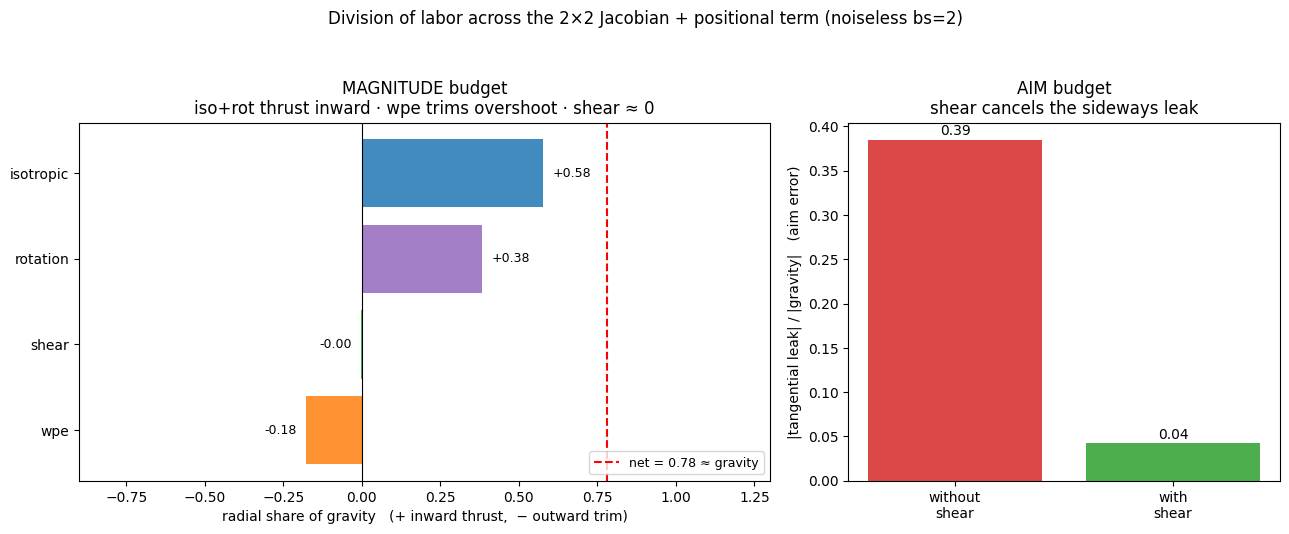

In [18]:
#| label: fig-division-of-labor
#| fig-cap: "Division of labor across the 2x2 Jacobian + positional term (noiseless bs=2). Magnitude budget: isotropic (+0.94) and rotation (+0.52) thrust inward, positional/wpe (-0.48) trims the overshoot, net ~ 0.99 = gravity; shear ~ 0. Aim budget: shear cancels the tangential leak (0.23 -> 0.04)."
#| code-fold: true
# ── Division of labor: what each channel's job is (magnitude budget + aim budget) ──
I2 = np.eye(2); R = np.array([[0., -1.], [1., 0.]]); DT = 0.2
mdl = model_noiseless; T = all_blocks.shape[1]; D = all_blocks.shape[-1]
w_k = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
r_t, r_pr = w_k[:, -1, :], w_k[:, -2, :]; r = np.linalg.norm(r_t, axis=1)
grav = -DT**2 * r_t / r[:, None]**3; gmag = np.linalg.norm(grav, axis=1); rhat = r_t / r[:, None]
d = r_t - r_pr; that = d - (d*rhat).sum(1, keepdims=True)*rhat; that /= np.linalg.norm(that, axis=1, keepdims=True)

Jr = all_blocks[:, T-1] - 2*I2; Jp = all_blocks[:, T-2] + 1*I2
def parts(J):
    ds  = (J[:, 0, 0] + J[:, 1, 1]) / 2
    a   = (J[:, 1, 0] - J[:, 0, 1]) / 2
    sym = (J + J.transpose(0, 2, 1)) / 2
    G   = sym - ((sym[:, 0, 0] + sym[:, 1, 1]) / 2)[:, None, None] * I2
    return ds, a, G
mv = lambda M, x: np.einsum('nij,nj->ni', M, x)
ds_r, a_r, G_r = parts(Jr); ds_p, a_p, G_p = parts(Jp)
iso = ds_r[:, None]*r_t + ds_p[:, None]*r_pr
rot = (a_r[:, None]*r_t + a_p[:, None]*r_pr) @ R.T
sym = mv(G_r, r_t) + mv(G_p, r_pr)
if 'pos' not in globals():                                  # slow part (embedding Jacobian); reuse if already computed
    pos = np.zeros_like(r_t)
    for i, wi in enumerate(w_k):
        pos[i] = mdl.compute_detached_jacobians_embedding(torch.tensor(wi, dtype=torch.float64).unsqueeze(0))[5][(T-1)*D:T*D].detach().numpy()

def rslope(u):
    proj = (u*grav).sum(1)/gmag
    return (gmag*proj).sum()/(gmag*gmag).sum()
tang = lambda u: (u*that).sum(1)/gmag
chans = [('isotropic', 'tab:blue', iso), ('rotation', 'tab:purple', rot),
         ('shear', 'tab:green', sym),    ('wpe', 'tab:orange', pos)]
rad = [rslope(u) for _, _, u in chans]
to = tang(iso + rot + pos); tf = to + tang(sym)                      # aim error without / with shear

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={'width_ratios': [1.6, 1]})
names = [c[0] for c in chans]; cols = [c[1] for c in chans]; yy = np.arange(len(chans))[::-1]
axA.barh(yy, rad, color=cols, alpha=0.85)
for yi, v in zip(yy, rad):
    axA.text(v + 0.03*np.sign(v), yi, f'{v:+.2f}', va='center', ha='left' if v > 0 else 'right', fontsize=9)
axA.axvline(0, color='k', lw=0.8)
axA.axvline(sum(rad), color='red', ls='--', lw=1.5, label=f'net = {sum(rad):.2f} ≈ gravity')
axA.set_yticks(yy); axA.set_yticklabels(names); axA.set_xlim(-0.9, 1.3)
axA.set_xlabel('radial share of gravity   (+ inward thrust,  − outward trim)')
axA.set_title('MAGNITUDE budget\niso+rot thrust inward · wpe trims overshoot · shear ≈ 0')
axA.legend(fontsize=9, loc='lower right')
vals = [np.median(np.abs(to)), np.median(np.abs(tf))]
axB.bar(['without\nshear', 'with\nshear'], vals, color=['tab:red', 'tab:green'], alpha=0.85)
for i, v in enumerate(vals): axB.text(i, v + 0.005, f'{v:.2f}', ha='center', fontsize=10)
axB.set_ylabel('|tangential leak| / |gravity|   (aim error)')
axB.set_title('AIM budget\nshear cancels the sideways leak')
fig.suptitle('Division of labor across the 2×2 Jacobian + positional term (noiseless bs=2)', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

In [19]:
#| code-fold: true
#| output: false
# Animate the noiseless gravity-kick decomposition along one example orbit -> figures/gravity_kick.gif
import os
from matplotlib.animation import FuncAnimation, PillowWriter
from analysis.data import load_orbital_params

os.makedirs('figures', exist_ok=True)
with contextlib.redirect_stdout(io.StringIO()):
    _trajs = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=OFFSET + 2000))
    _ops   = load_orbital_params(DATA_DIR, num_trajectories_needed=OFFSET + 2000)
_ecc  = np.array([p['e'] for p in _ops])
_idx  = next(i for i in range(OFFSET, OFFSET + 2000) if 0.38 < _ecc[i] < 0.42)  # a moderately eccentric test orbit
orbit = _trajs[_idx]

frames = NT.gravity_kick_frames(model_noiseless, orbit, dt=0.2)
META  = [('iso', 'tab:blue'), ('rot', 'tab:purple'), ('shear', 'tab:green'), ('wpe', 'tab:orange')]
SCALE = 0.28 / np.median([np.linalg.norm(f[k]) for f in frames for k in ('iso', 'rot', 'shear', 'wpe')])
lim   = np.abs(orbit).max() * 1.15

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 6.3))
def _draw(i):
    f = frames[i]; axL.clear(); axR.clear()
    axL.plot(orbit[:, 0], orbit[:, 1], color='lightgray', lw=1, zorder=0)
    axL.scatter(0, 0, marker='*', s=300, color='gold', edgecolor='k', zorder=5)
    axL.scatter(*f['r_t'], color='k', s=28, zorder=4)
    v = f['verlet']
    for k, c in META:
        axL.annotate('', xy=v + f[k]*SCALE, xytext=v, arrowprops=dict(arrowstyle='->', color=c, lw=2))
    axL.annotate('', xy=v + f['grav']*SCALE, xytext=v, arrowprops=dict(arrowstyle='->', color='k', lw=1.5, ls='--'))
    axL.set_xlim(-lim, lim * 1.4); axL.set_ylim(-lim, lim)   # extend +x
    axL.set_title(f'orbit  (vectors x{SCALE:.0f};  step {i+1}/{len(frames)})')
    rhat = f['r_t']/np.linalg.norm(f['r_t']); dd = f['r_t'] - f['r_pr']
    that = dd - (dd @ rhat)*rhat; that /= np.linalg.norm(that); gmag = np.linalg.norm(f['grav'])
    loc = lambda u: np.array([(u @ that)/gmag, -(u @ rhat)/gmag])
    p = np.zeros(2)
    for k, c in META:
        wv = loc(f[k]); axR.annotate('', xy=p + wv, xytext=p, arrowprops=dict(arrowstyle='->', color=c, lw=2.4))
        axR.text(*(p + wv/2), k, color=c, fontsize=8, ha='center'); p = p + wv
    axR.scatter(0, 1, marker='*', s=200, color='k', zorder=5, label='gravity')
    axR.scatter(*p, color='red', s=45, zorder=6, label='sum of components')
    axR.axhline(0, color='gray', lw=0.4); axR.axvline(0, color='gray', lw=0.4)
    axR.set_xlim(-2.2, 2.2); axR.set_ylim(-1.5, 3.8)          # extend +y
    axR.set_xlabel('tangential / |gravity|'); axR.set_ylabel('inward-radial / |gravity|')
    axR.set_title('components -> gravity (local frame)'); axR.legend(loc='lower right', fontsize=8)

_gif_path = 'figures/gravity_kick.gif'
if os.path.exists(_gif_path):
    os.remove(_gif_path)
FuncAnimation(fig, _draw, frames=len(frames), interval=90).save(_gif_path, writer=PillowWriter(fps=12))
plt.close(fig)


Animated along a full orbit, the division of labor becomes vivid: as the planet sweeps from aphelion to perihelion the four channels grow, shrink and re-apportion the load among themselves — yet their sum tracks the inward $1/r^2$ gravity vector at *every* step.

![**Left:** the four Jacobian channels (isotropic, rotation, shear) plus the positional (wpe) term, drawn from the Verlet point as the planet moves along one orbit (arrows scaled for visibility; dashed black = ideal gravity). **Right:** the same four vectors tip-to-tail in the local (radial, tangential) frame normalised by $|\text{gravity}|$; their sum (red) lands on the gravity target $(0,1)$ throughout. The channels continually re-apportion the load, but always reconstruct the inward $1/r^2$ force.](figures/gravity_kick.gif){#fig-gravity-gif}


### Two mechanisms for one task

@fig-division-of-labor makes the roles explicit. On the radial (magnitude) axis the **isotropic** (+0.94) and **rotation** (+0.52) channels thrust inward while the **positional** term (−0.48) trims the overshoot, summing to $\approx 1.0$ — exactly gravity. The **shear** channel supplies almost no magnitude but does the *steering*: it cancels the other channels' tangential leak (aim error $0.23\to0.04$), pointing the net kick precisely at the focus.

Putting the two halves together, the short-context transformer solves the same next-step task two different ways depending on the training distribution. **With noisy context** it learns a smooth, noise-robust *local circular-orbit heuristic* — rotate by the circular angle, ignore angular momentum and radial motion. **Without noise** it learns the genuine article: a *Verlet integrator plus Newtonian gravity*, with the $1/r^2$ force built across the isotropic, rotation, and shear channels of its Jacobian and trimmed to unit strength by the positional embedding. It is the inductive bias of the training data — not the architecture — that decides which world model emerges.


## Why the mechanism matters: rolling out the two world models

A correct *one-step* force is only useful if it integrates into a correct *orbit*. To see the practical shadow of the two mechanisms, we seed each model with the first two positions of a held-out **eccentric** orbit and let it predict autoregressively for 49 steps — feeding each prediction back as the next input — alongside an ideal Verlet integrator and the true orbit.


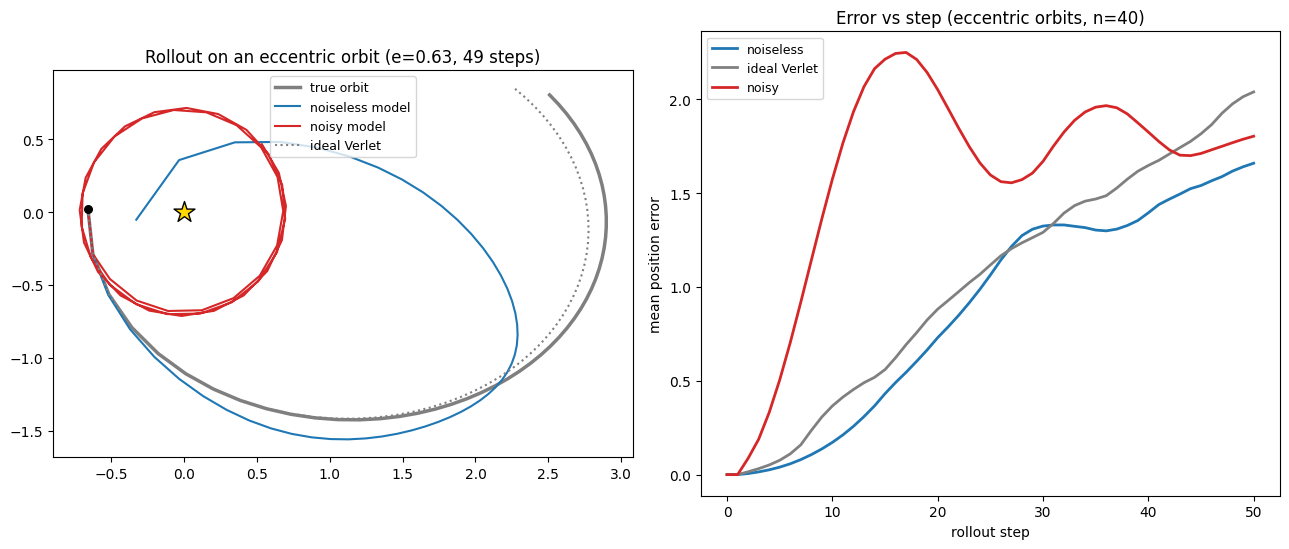

In [20]:
#| label: fig-rollout
#| fig-cap: "Autoregressive rollout on eccentric orbits (0.5 < e < 0.7). Left: one example orbit - the noiseless model (blue) tracks the true ellipse as well as ideal Verlet, while the noisy model (red) collapses it into a circle. Right: mean position error vs rollout step over 40 orbits - the noisy heuristic errs from the first steps (bounded, since it settles on a wrong circular path); the noiseless model stays lowest, even beating dt=0.2 Verlet at long horizon."
#| code-fold: true
from analysis.elm import rollout, rollout_verlet
from analysis.data import load_orbital_params

with contextlib.redirect_stdout(io.StringIO()):
    _tr = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=OFFSET + 2000))
    _op = load_orbital_params(DATA_DIR, num_trajectories_needed=OFFSET + 2000)
_e  = np.array([p['e'] for p in _op])
ecc = [i for i in range(OFFSET, OFFSET + 2000) if 0.5 < _e[i] < 0.7][:40]
N   = 49

errs = {'noiseless': [], 'ideal Verlet': [], 'noisy': []}
for i in ecc:
    tr = _tr[i]; s = tr[:2]
    errs['noiseless'].append(np.linalg.norm(rollout(model_noiseless, s, N) - tr[:N+2], axis=1))
    errs['ideal Verlet'].append(np.linalg.norm(rollout_verlet(s, N)        - tr[:N+2], axis=1))
    errs['noisy'].append(np.linalg.norm(rollout(model_bs2, s, N)            - tr[:N+2], axis=1))

ei = ecc[0]; true = _tr[ei]; s = true[:2]
rn, rv, rx = rollout(model_noiseless, s, N), rollout_verlet(s, N), rollout(model_bs2, s, N)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.6))
axA.plot(true[:N+2, 0], true[:N+2, 1], 'k-', lw=2.5, alpha=0.5, label='true orbit')
axA.plot(rn[:, 0], rn[:, 1], '-',  color='tab:blue',   lw=1.5, label='noiseless model')
axA.plot(rx[:, 0], rx[:, 1], '-',  color='tab:red',    lw=1.5, label='noisy model')
axA.plot(rv[:, 0], rv[:, 1], ':',  color='gray',       lw=1.5, label='ideal Verlet')
axA.scatter(0, 0, marker='*', s=250, color='gold', edgecolor='k', zorder=5)
axA.scatter(*s[0], color='k', s=30, zorder=5)
axA.set_aspect('equal'); axA.legend(fontsize=9)
axA.set_title(f'Rollout on an eccentric orbit (e={_e[ei]:.2f}, {N} steps)')
for name, c in [('noiseless', 'tab:blue'), ('ideal Verlet', 'gray'), ('noisy', 'tab:red')]:
    axB.plot(range(N + 2), np.array(errs[name]).mean(0), color=c, lw=2, label=name)
axB.set_xlabel('rollout step'); axB.set_ylabel('mean position error')
axB.set_title(f'Error vs step (eccentric orbits, n={len(ecc)})'); axB.legend(fontsize=9)
fig.tight_layout(); plt.show()


@fig-rollout is the practical shadow of the mechanism. On an eccentric orbit the noiseless model tracks the true ellipse — as tightly as an ideal Verlet integrator, and *better* at long horizon (it has learned small corrections beyond leading-order Verlet). The noisy model cannot: its local circular-orbit heuristic quite literally **turns the ellipse into a circle**, missing the true orbit from the very first steps. Its error is large but *bounded* — it settles onto a stable, wrong, circular path rather than diverging.

This is the point of reading out *how* a model computes, not just *what* it encodes. Both models "predict planetary motion"; both, by a linear probe, look like they know about force and geometry. But only one has learned a mechanism — Newtonian gravity — that generalises across orbit shapes; the other has learned a shortcut that works precisely where it was, in effect, assumed. Which one a transformer becomes is set not by its architecture but by the inductive bias of its training distribution.
